# VegetableVision AI — Multi-Vegetable Segmentation & Measurement (Kaggle)

This notebook trains one YOLO **instance-segmentation** model for multiple vegetable/fruit classes, then measures every detected instance.

**Dataset:** the configured Roboflow project has 28 classes (Soybean, apple, banana, broccoli, cabbage, capsicum, carrot, cauliflower, chilli, corn, cucumber, eggplant, garlic, ginger, grapes, lemon, mango, onion, orange, pear, peas, pineapple, potato, radish, strawberry, sweetpotato, tomato, watermelon).

- No manual class-ID mapping is needed: the notebook selects classes by their names and remaps labels automatically.
- The dataset must contain **segmentation polygon annotations**, not only bounding boxes.
- Measurements are approximate 2D dimensions. Pixel values need no calibration; centimetres require a real known-size reference in the same image and approximately the same plane/depth.
- Start with all classes or edit `KEEP_CLASSES` to choose a subset. Rare classes may need more labelled images.


## 1. Setup and GPU check

In [1]:
!pip install -q ultralytics roboflow

import os, sys, json, shutil, random
from pathlib import Path

import yaml
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU detected. Turn on a GPU accelerator in the notebook settings before training.")

import ultralytics
print("Ultralytics:", ultralytics.__version__)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 87.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 5.2 MB/s eta 0:00:00
Torch: 2.11.0+cu128 | CUDA available: True
GPU: Tesla T4
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.178


## 2. Configuration

For all classes in the configured Roboflow dataset, leave `KEEP_CLASSES` as the full list below. To train a subset, remove class names you do not need. Names must match the dataset's `data.yaml` names (case-insensitive).

For Roboflow, store the API key in **Kaggle Secrets** under `ROBOFLOW_API_KEY`. Do not paste API keys directly into notebook code.


In [2]:
DATA_SOURCE = "roboflow"  # "roboflow" or "kaggle_input"

RF_WORKSPACE = "manthans-workspace-whuel"
RF_PROJECT = "fruit-and-vegetable-gmtmi-bguha-dastt"
RF_VERSION = 1
KAGGLE_INPUT_DIR = "/kaggle/input/your-dataset-name"

# 28 classes available in the configured dataset. Edit this list to select a subset.
KEEP_CLASSES = [
    "Soybean", "apple", "banana", "broccoli", "cabbage", "capsicum",
    "carrot", "cauliflower", "chilli", "corn", "cucumber", "eggplant",
    "garlic", "ginger", "grapes", "lemon", "mango", "onion", "orange",
    "pear", "peas", "pineapple", "potato", "radish", "strawberry",
    "sweetpotato", "tomato", "watermelon"
]
NAME_ALIASES = {}  # e.g. {"bell pepper": "capsicum"}

MODEL_CANDIDATES = ["yolo11n-seg.pt", "yolov8n-seg.pt"]
EPOCHS = 50
IMGSZ = 640
BATCH = 16
CONF = 0.25

# "none" always gives pixel measurements; use "aruco" when a real marker is visible.
REFERENCE_METHOD = "aruco"
ARUCO_MARKER_SIZE_CM = 5.0
ARUCO_DICT_NAME = "DICT_4X4_50"

# Optional independently measured test set for length/width error evaluation.
OWN_TEST_DIR = "/kaggle/input/your-test-photos"
OWN_TEST_CSV = "/kaggle/input/your-test-photos/measurements.csv"

WORK = Path("/kaggle/working") if Path("/kaggle").exists() else Path("./work")
WORK.mkdir(parents=True, exist_ok=True)
DATASET_DIR = WORK / "dataset"
EXPORT_DIR = WORK / "export"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
print("Working directory:", WORK.resolve())
print("Selected classes:", len(KEEP_CLASSES), KEEP_CLASSES)


Working directory: /kaggle/working
Selected classes: 28 ['Soybean', 'apple', 'banana', 'broccoli', 'cabbage', 'capsicum', 'carrot', 'cauliflower', 'chilli', 'corn', 'cucumber', 'eggplant', 'garlic', 'ginger', 'grapes', 'lemon', 'mango', 'onion', 'orange', 'pear', 'peas', 'pineapple', 'potato', 'radish', 'strawberry', 'sweetpotato', 'tomato', 'watermelon']


## 3. Download or locate the dataset

In [3]:
if DATA_SOURCE == "roboflow":
    from roboflow import Roboflow
    try:
        from kaggle_secrets import UserSecretsClient
        api_key = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")
    except Exception:
        api_key = os.environ.get("ROBOFLOW_API_KEY")
    if not api_key:
        raise RuntimeError("No Roboflow API key found. Add a Kaggle Secret named ROBOFLOW_API_KEY.")

    rf = Roboflow(api_key=api_key)
    version = rf.workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION)
    raw_dir = WORK / "raw_dataset"
    version.download("yolov8", location=str(raw_dir))
    SRC_ROOT = raw_dir
else:
    SRC_ROOT = Path(KAGGLE_INPUT_DIR)

yaml_files = list(SRC_ROOT.rglob("data.yaml"))
assert yaml_files, f"No data.yaml found under {SRC_ROOT}. Check the path or dataset format."
SRC_ROOT = yaml_files[0].parent
print("Dataset root:", SRC_ROOT)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/raw_dataset in yolov8:: 100%|██████████| 5876/5876 [00:00<00:00, 6074.84it/s]


Dataset root: /kaggle/working/raw_dataset


## 4. Inspect source dataset and confirm segmentation labels

In [4]:
def read_names(yaml_path):
    cfg = yaml.safe_load(open(yaml_path))
    names = cfg["names"]
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    return list(names)


SRC_NAMES = read_names(SRC_ROOT / "data.yaml")
print("Classes in source dataset:", SRC_NAMES)

SPLIT_DIRS = [s for s in ["train", "valid", "val", "test"] if (SRC_ROOT / s / "images").exists()]
for s in SPLIT_DIRS:
    n_img = len(list((SRC_ROOT / s / "images").glob("*")))
    print(f"  {s}: {n_img} images")

poly_lines, box_lines = 0, 0
label_files = list((SRC_ROOT / "train" / "labels").glob("*.txt"))
for lf in random.sample(label_files, min(200, len(label_files))):
    for line in open(lf):
        n = len(line.split())
        if n > 5:
            poly_lines += 1
        elif n == 5:
            box_lines += 1
print(f"\nSampled labels -> polygon lines: {poly_lines} | box-only lines: {box_lines}")
if poly_lines == 0:
    print("WARNING: no polygon labels found. This dataset cannot be used for segmentation training.")

Classes in source dataset: ['Soybean', 'apple', 'banana', 'broccoli', 'cabbage', 'capsicum', 'carrot', 'cauliflower', 'chilli', 'corn', 'cucumber', 'eggplant', 'garlic', 'ginger', 'grapes', 'lemon', 'mango', 'onion', 'orange', 'pear', 'peas', 'pineapple', 'potato', 'radish', 'strawberry', 'sweetpotato', 'tomato', 'watermelon']
  train: 2082 images
  valid: 569 images
  test: 285 images

Sampled labels -> polygon lines: 275 | box-only lines: 0


## 5. Filter the selected classes and remap labels

In [5]:
final_index = {n.lower(): i for i, n in enumerate(KEEP_CLASSES)}


def target_index(src_name):
    n = src_name.strip().lower()
    n = NAME_ALIASES.get(n, n)
    return final_index.get(n)


if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)

counts = {}
skipped_box_lines = 0
for split in SPLIT_DIRS:
    out_split = "valid" if split == "val" else split
    (DATASET_DIR / out_split / "images").mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / out_split / "labels").mkdir(parents=True, exist_ok=True)
    counts[out_split] = {n: 0 for n in KEEP_CLASSES}
    kept_images = 0

    for lf in (SRC_ROOT / split / "labels").glob("*.txt"):
        new_lines = []
        for line in open(lf):
            parts = line.split()
            if len(parts) < 7:
                skipped_box_lines += 1
                continue
            idx = target_index(SRC_NAMES[int(parts[0])])
            if idx is None:
                continue
            new_lines.append(" ".join([str(idx)] + parts[1:]))
            counts[out_split][KEEP_CLASSES[idx]] += 1
        if not new_lines:
            continue
        img_path = next((SRC_ROOT / split / "images").glob(lf.stem + ".*"), None)
        if img_path is None:
            continue
        shutil.copy2(img_path, DATASET_DIR / out_split / "images" / img_path.name)
        (DATASET_DIR / out_split / "labels" / lf.name).write_text("\n".join(new_lines))
        kept_images += 1
    print(f"{out_split}: kept {kept_images} images")

print("\nInstances per class:")
print(pd.DataFrame(counts).T)
print("Box-only lines skipped:", skipped_box_lines)

data_cfg = {
    "path": str(DATASET_DIR.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "names": {i: n for i, n in enumerate(KEEP_CLASSES)},
}
if (DATASET_DIR / "test" / "images").exists():
    data_cfg["test"] = "test/images"

DATA_YAML = DATASET_DIR / "vegetables.yaml"
yaml.safe_dump(data_cfg, open(DATA_YAML, "w"), sort_keys=False)
print("\nWrote", DATA_YAML)

train: kept 2081 images
valid: kept 569 images
test: kept 285 images

Instances per class:
       Soybean  apple  banana  broccoli  cabbage  capsicum  carrot  \
train       25    163     111         3       74       115     302   
valid        7     48      34         2       22        46      75   
test         5     22      21         0        8        13      45   

       cauliflower  chilli  corn  ...  orange  pear  peas  pineapple  potato  \
train           41      60    41  ...     226    73    74         94     327   
valid           11      49     6  ...      56    16     6         15     101   
test             3      19     5  ...      20     1     1         27      46   

       radish  strawberry  sweetpotato  tomato  watermelon  
train      31          79           70      45         105  
valid       3          19            9      19          22  
test        4          15            4       4           7  

[3 rows x 28 columns]
Box-only lines skipped: 0

Wrote /kaggle

## 6. Train the multi-class segmentation model

In [6]:
from ultralytics import YOLO

try:
    from ultralytics import settings
    settings.update({"wandb": False})
except Exception:
    pass
os.environ["WANDB_DISABLED"] = "true"

model, MODEL_NAME = None, None
for w in MODEL_CANDIDATES:
    try:
        model = YOLO(w)
        MODEL_NAME = w
        print("Using base model:", w)
        break
    except Exception as e:
        print(f"Could not load {w}: {str(e)[:120]}")
assert model is not None, "No base model could be loaded. Check that Internet is turned on."

results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=0 if torch.cuda.is_available() else "cpu",
    project=str(WORK / "runs"),
    name="veg_seg",
    exist_ok=True,
    patience=15,
    workers=2,
    plots=True,
)

BEST = Path(model.trainer.best)
RUN_DIR = BEST.parent.parent
print("\nBest weights:", BEST)

Using base model: yolo11n-seg.pt
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/vegetables.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=veg_seg, nbs=

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/50      3.71G     0.5252      1.218      1.979       1.09          0          2        640: 100% ━━━━━━━━━━━━ 131/131 4.6it/s 28.4s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 2.8it/s 6.4s0.3s
                   all        569        839      0.647       0.47      0.503      0.406      0.652      0.451      0.503      0.414

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       3/50      3.71G     0.5486      1.182      1.612        1.1          0          4        640: 100% ━━━━━━━━━━━━ 131/131 4.7it/s 28.1s0.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 3.1it/s 5.8s0.3s
                   all        569        839      0.698      0.485      0.532      0.422      0.673      0.492      0.522     

## 7. Evaluate segmentation performance

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n-seg summary (fused): 114 layers, 2,856,028 parameters, 0 gradients, 9.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1221.0±1296.6 MB/s, size: 84.7 KB)
val: Scanning /kaggle/working/dataset/valid/labels.cache... 569 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 569/569 198.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 4.4it/s 8.3s0.2s
                   all        569        839      0.714      0.704      0.727      0.623      0.715      0.702      0.725      0.619
Speed: 1.1ms preprocess, 5.7ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /kaggle/working/runs/segment/val
Box  mAP50: 0.727 | mAP50-95: 0.623
Mask mAP50: 0.725 | mAP50-95: 0.619


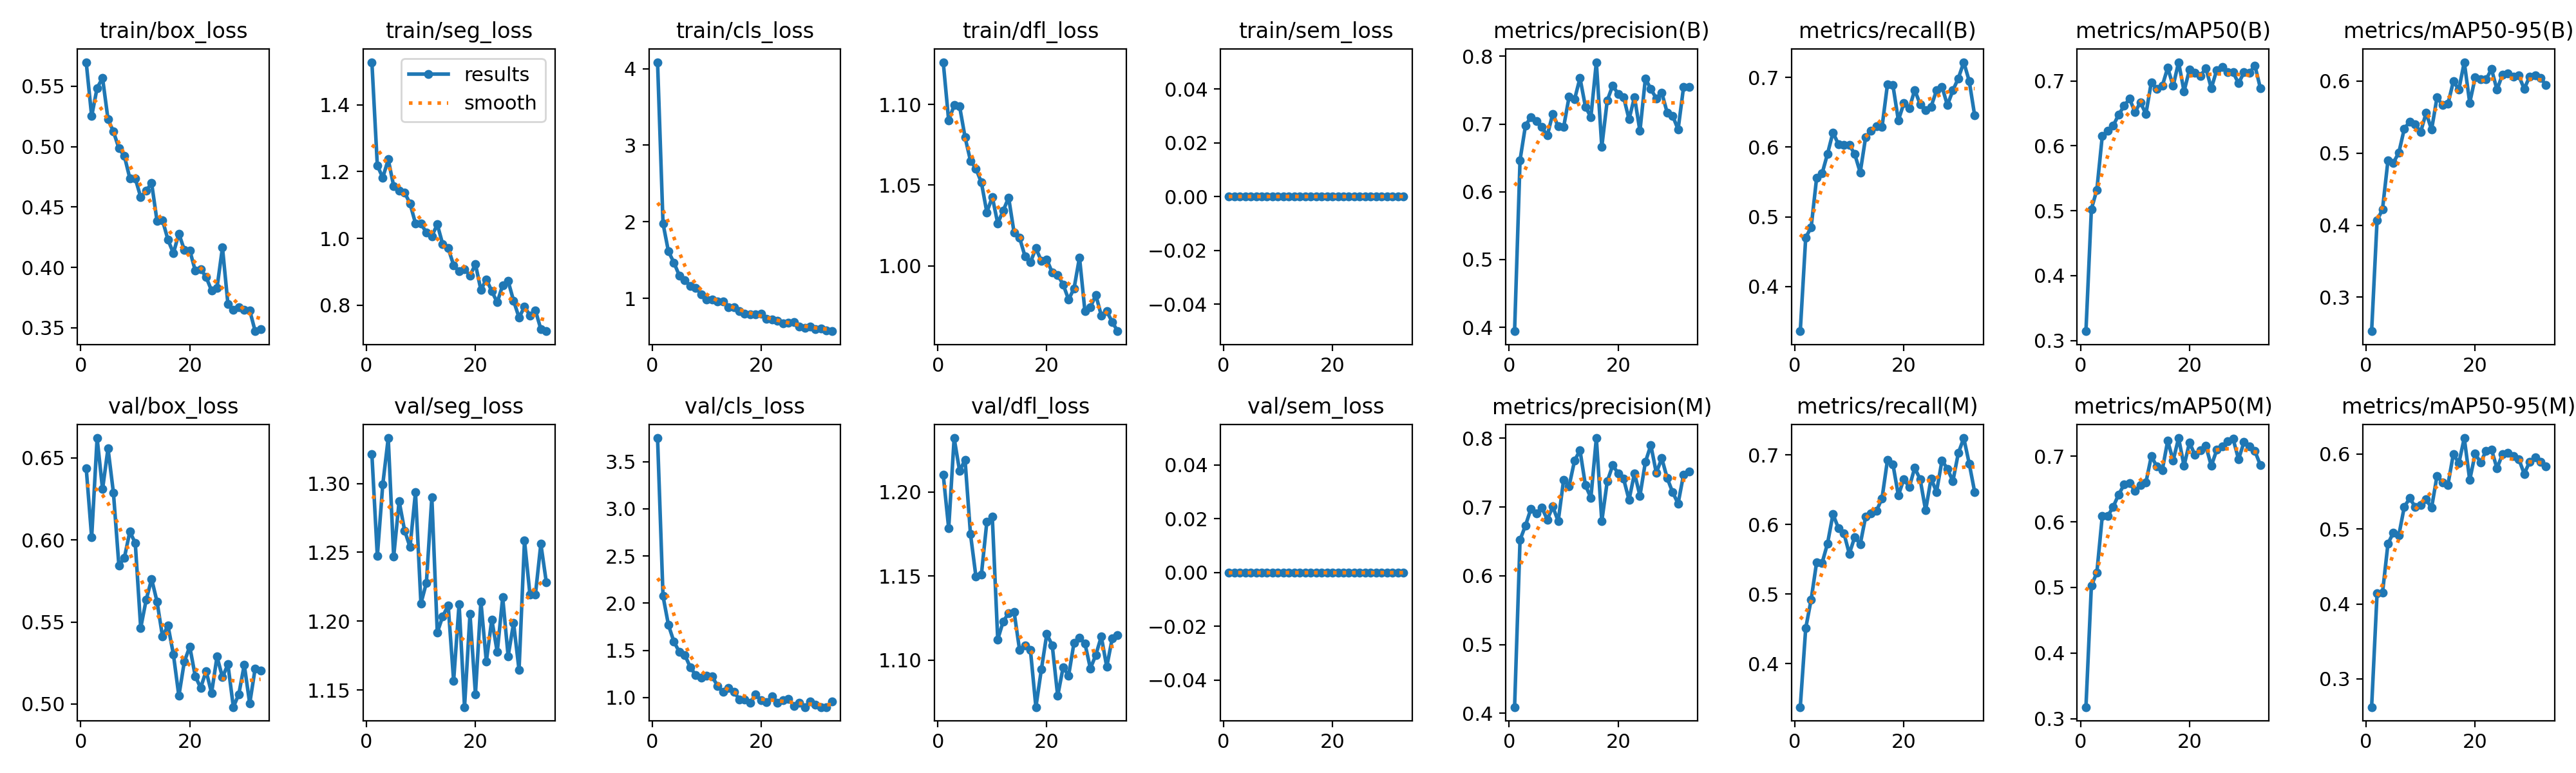

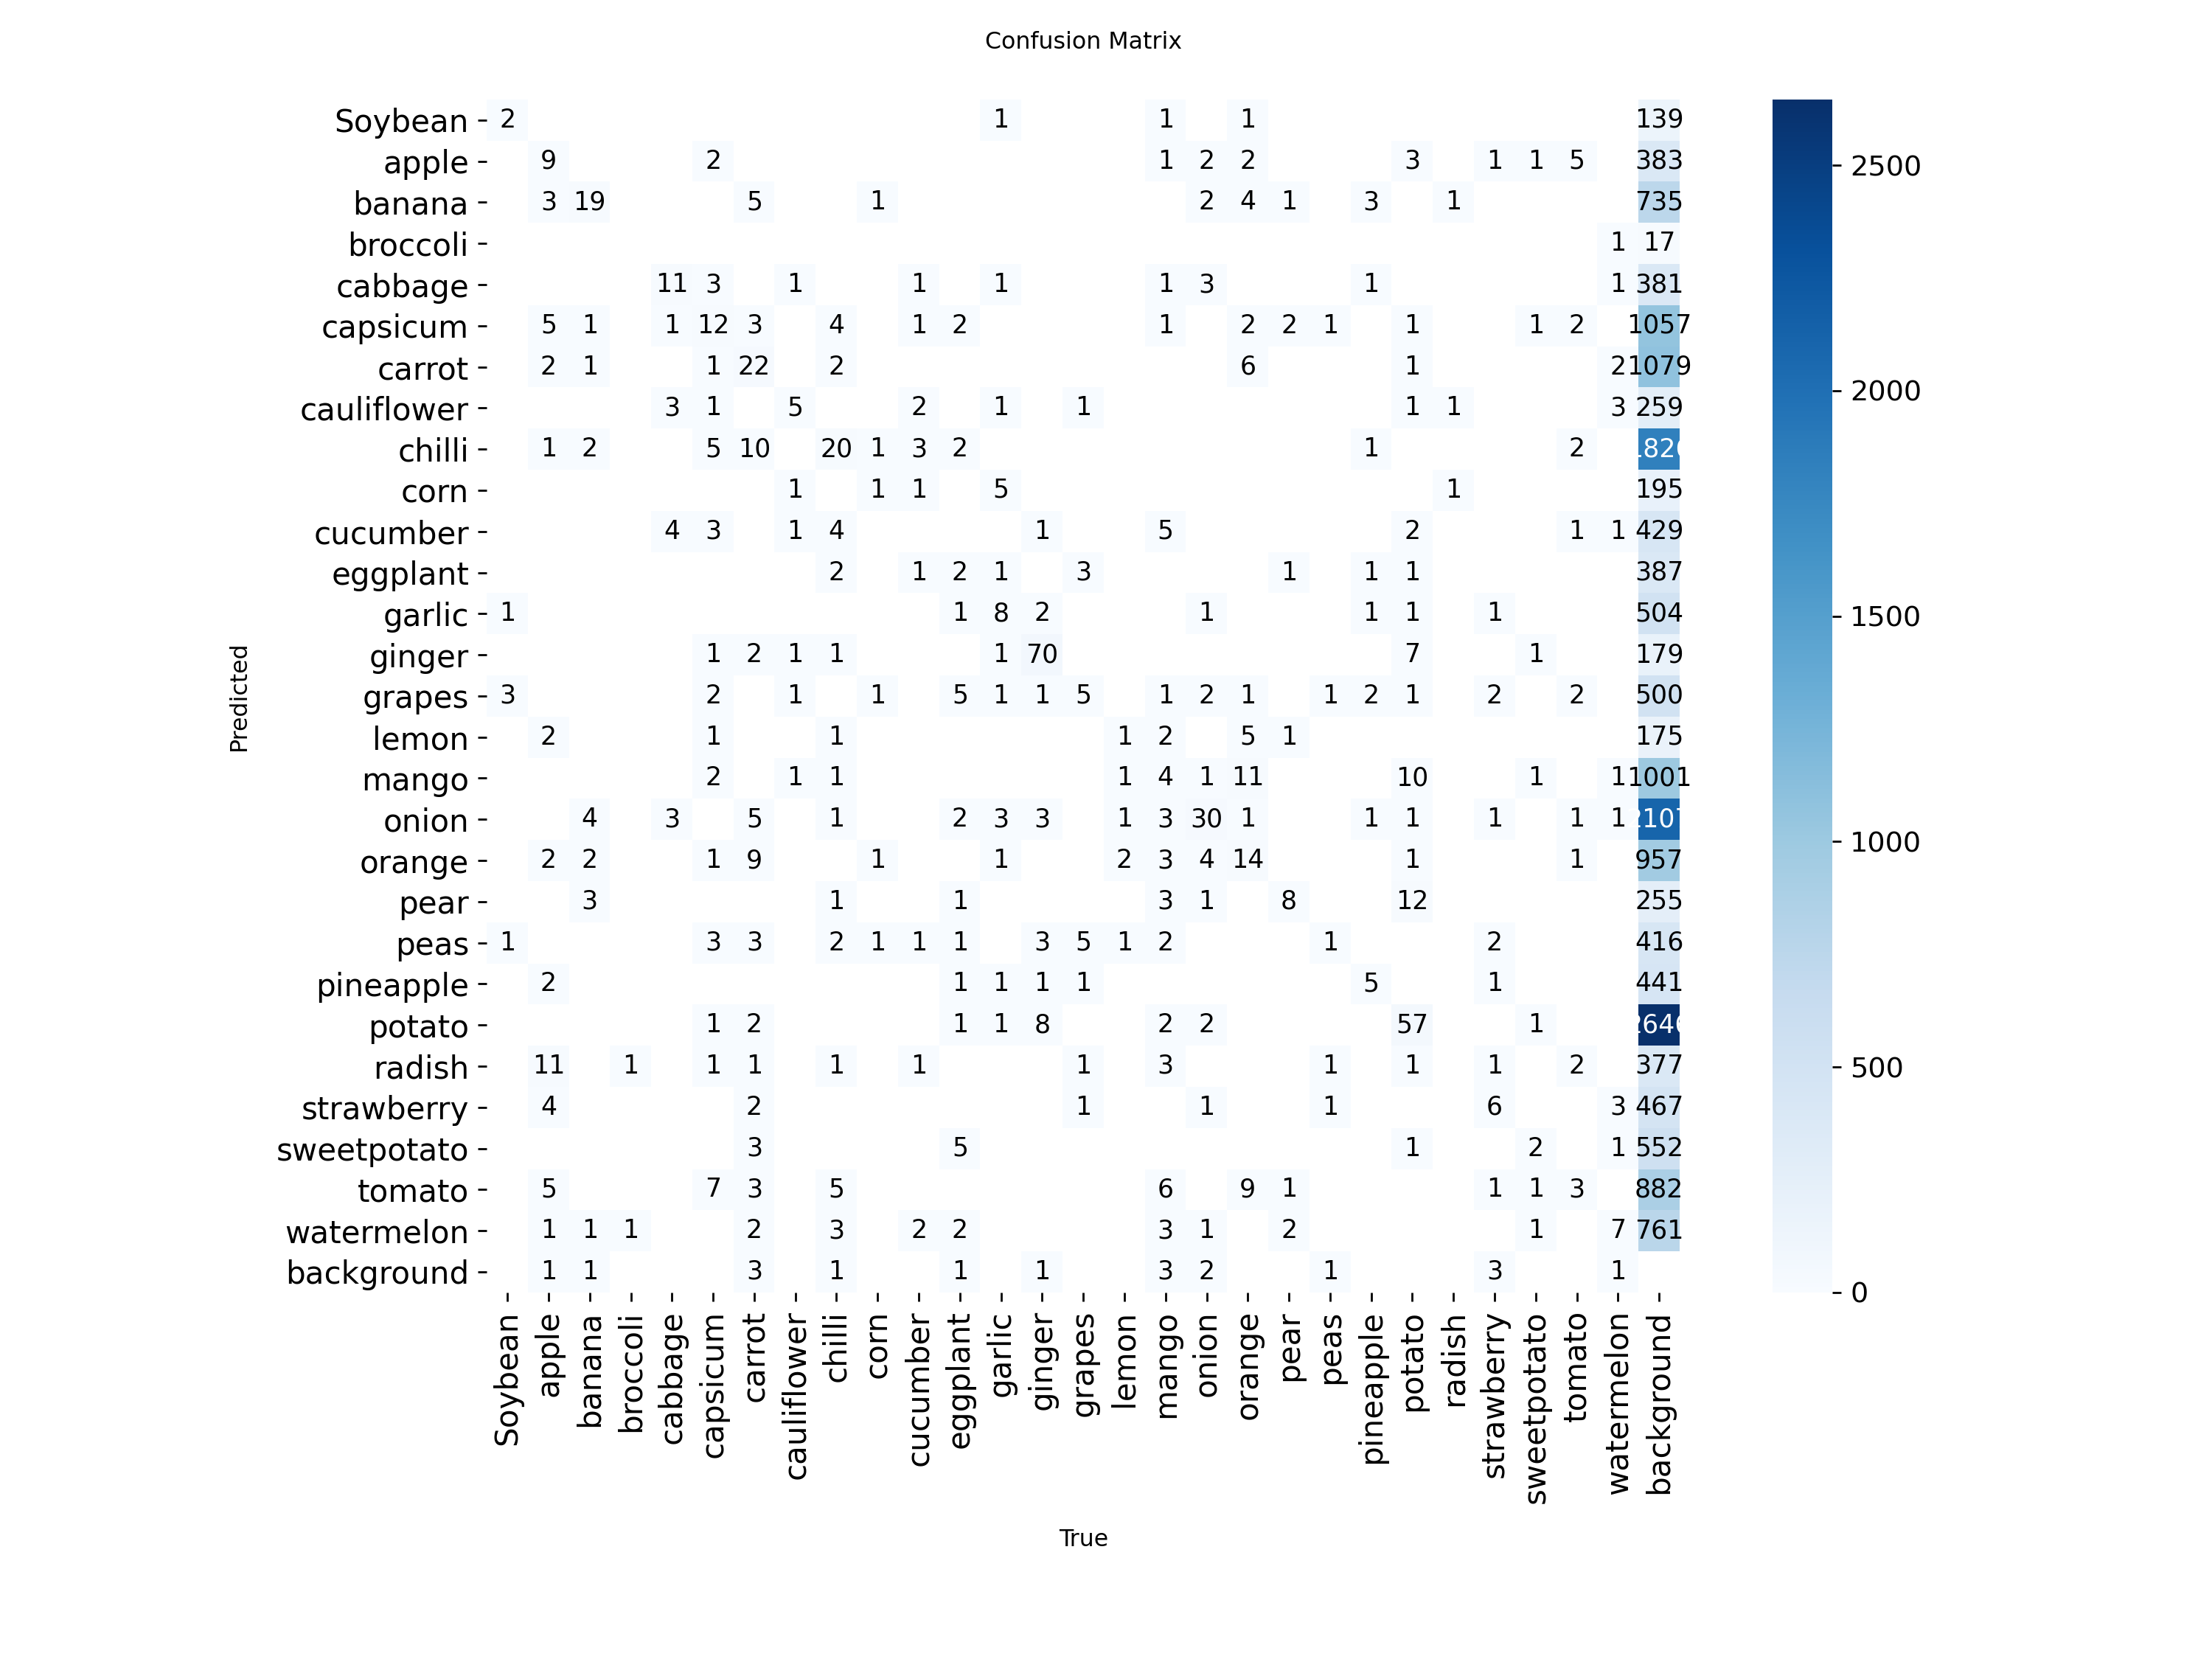

In [7]:
best_model = YOLO(str(BEST))
metrics = best_model.val(data=str(DATA_YAML), imgsz=IMGSZ, split="val", verbose=False)

print(f"Box  mAP50: {metrics.box.map50:.3f} | mAP50-95: {metrics.box.map:.3f}")
print(f"Mask mAP50: {metrics.seg.map50:.3f} | mAP50-95: {metrics.seg.map:.3f}")

from IPython.display import Image, display
for name in ["results.png", "confusion_matrix.png"]:
    p = RUN_DIR / name
    if p.exists():
        display(Image(filename=str(p), width=800))

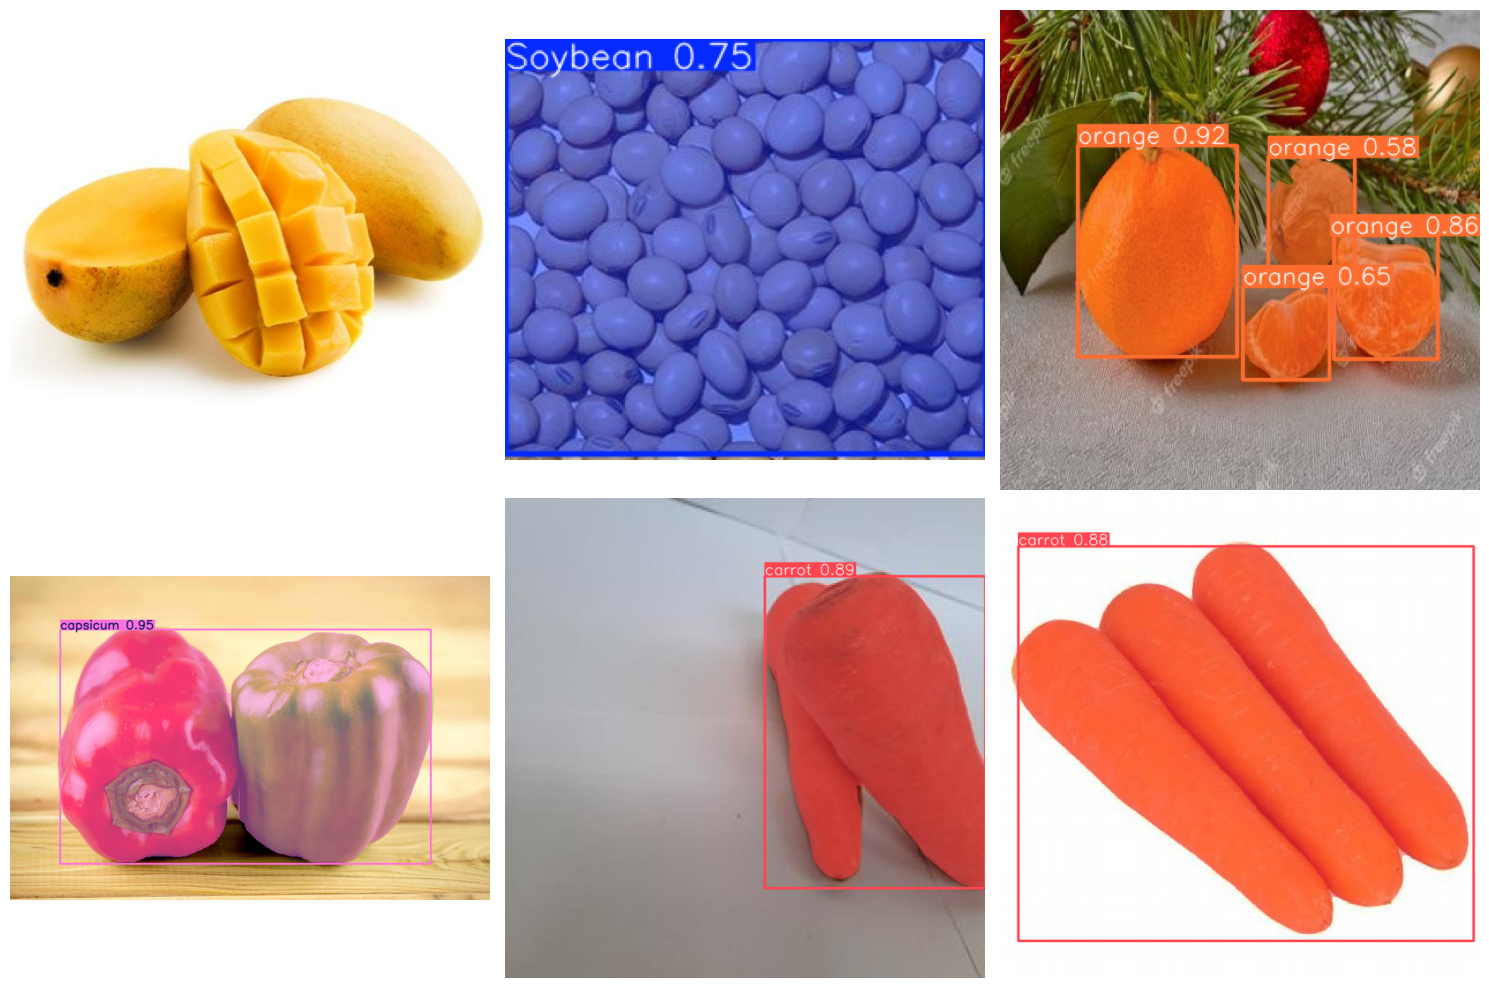

In [8]:
val_imgs = sorted((DATASET_DIR / "valid" / "images").glob("*"))
sample = random.sample(val_imgs, min(6, len(val_imgs)))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax in axes.ravel():
    ax.axis("off")
for ax, p in zip(axes.ravel(), sample):
    r = best_model.predict(str(p), conf=CONF, verbose=False)[0]
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
plt.tight_layout()
plt.show()

## 8. Measurement and calibration helpers

`measure_polygon()` returns length/width from a rotated rectangle fitted to the segmentation polygon. It measures the visible 2D shape, not hidden or true 3D dimensions.


In [9]:
%%writefile /kaggle/working/export/measurement.py
import cv2
import numpy as np


def measure_polygon(polygon_xy, pixels_per_cm=None):
    pts = np.asarray(polygon_xy, dtype=np.float32).reshape(-1, 1, 2)
    if len(pts) < 3:
        return None
    (cx, cy), (w, h), angle = cv2.minAreaRect(pts)
    box = cv2.boxPoints(((cx, cy), (w, h), angle))
    length_px = float(max(w, h))
    width_px = float(min(w, h))
    area_px = float(cv2.contourArea(pts))
    out = {
        "length_px": round(length_px, 2),
        "width_px": round(width_px, 2),
        "area_px": round(area_px, 2),
        "angle_degrees": round(float(angle), 2),
        "box_points": box.tolist(),
        "length_cm": None,
        "width_cm": None,
        "area_cm2": None,
    }
    if pixels_per_cm and pixels_per_cm > 0:
        out["length_cm"] = round(length_px / pixels_per_cm, 2)
        out["width_cm"] = round(width_px / pixels_per_cm, 2)
        out["area_cm2"] = round(area_px / (pixels_per_cm ** 2), 2)
    return out


def measure_mask(mask, pixels_per_cm=None):
    binary = (np.asarray(mask) > 0).astype(np.uint8) * 255
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    contour = max(contours, key=cv2.contourArea)
    return measure_polygon(contour.reshape(-1, 2), pixels_per_cm)


def draw_measurement(image_bgr, polygon_xy, result, label=""):
    img = image_bgr.copy()
    pts = np.asarray(polygon_xy, dtype=np.int32).reshape(-1, 1, 2)
    cv2.polylines(img, [pts], True, (0, 255, 0), 2)
    box = np.asarray(result["box_points"], dtype=np.int32).reshape(-1, 1, 2)
    cv2.polylines(img, [box], True, (255, 0, 0), 2)
    if result["length_cm"] is not None:
        text = f"{label} L={result['length_cm']}cm W={result['width_cm']}cm"
    else:
        text = f"{label} L={result['length_px']}px W={result['width_px']}px"
    x, y = int(pts[:, 0, 0].min()), int(pts[:, 0, 1].min())
    cv2.putText(img, text.strip(), (x, max(20, y - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2, cv2.LINE_AA)
    return img

Writing /kaggle/working/export/measurement.py


In [10]:
%%writefile /kaggle/working/export/calibration.py
import cv2
import numpy as np

A4_LONG_CM = 29.7
A4_SHORT_CM = 21.0


def _dist(a, b):
    return float(np.linalg.norm(np.asarray(a) - np.asarray(b)))


def order_points(pts):
    pts = np.asarray(pts, dtype=np.float32).reshape(4, 2)
    s = pts.sum(axis=1)
    d = np.diff(pts, axis=1).ravel()
    tl, br = pts[np.argmin(s)], pts[np.argmax(s)]
    tr, bl = pts[np.argmin(d)], pts[np.argmax(d)]
    return np.array([tl, tr, br, bl], dtype=np.float32)


def generate_aruco_marker(marker_id=0, size_px=600, dict_name="DICT_4X4_50", border_px=100):
    aruco = cv2.aruco
    dictionary = aruco.getPredefinedDictionary(getattr(aruco, dict_name))
    if hasattr(aruco, "generateImageMarker"):
        marker = aruco.generateImageMarker(dictionary, marker_id, size_px)
    else:
        marker = aruco.drawMarker(dictionary, marker_id, size_px)
    return cv2.copyMakeBorder(marker, border_px, border_px, border_px, border_px,
                              cv2.BORDER_CONSTANT, value=255)


def detect_aruco(image_bgr, marker_size_cm, dict_name="DICT_4X4_50"):
    aruco = cv2.aruco
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    dictionary = aruco.getPredefinedDictionary(getattr(aruco, dict_name))
    if hasattr(aruco, "ArucoDetector"):
        detector = aruco.ArucoDetector(dictionary, aruco.DetectorParameters())
        corners, ids, _ = detector.detectMarkers(gray)
    else:
        corners, ids, _ = aruco.detectMarkers(gray, dictionary,
                                              parameters=aruco.DetectorParameters_create())
    if ids is None or len(corners) == 0:
        return None
    c = corners[0].reshape(4, 2)
    sides = [_dist(c[i], c[(i + 1) % 4]) for i in range(4)]
    return {
        "pixels_per_cm": float(np.mean(sides)) / float(marker_size_cm),
        "corners": c.tolist(),
        "method": "aruco",
    }


def detect_a4(image_bgr, min_area_fraction=0.10, ratio_tolerance=0.20):
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, th = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    contours, _ = cv2.findContours(th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    img_area = gray.shape[0] * gray.shape[1]

    quad = None
    for c in sorted(contours, key=cv2.contourArea, reverse=True)[:5]:
        if cv2.contourArea(c) < min_area_fraction * img_area:
            break
        approx = cv2.approxPolyDP(c, 0.02 * cv2.arcLength(c, True), True)
        if len(approx) == 4 and cv2.isContourConvex(approx):
            quad = approx.reshape(4, 2)
            break
    if quad is None:
        return None

    tl, tr, br, bl = order_points(quad)
    side_a = (_dist(tl, tr) + _dist(bl, br)) / 2
    side_b = (_dist(tl, bl) + _dist(tr, br)) / 2
    long_px, short_px = max(side_a, side_b), min(side_a, side_b)
    if abs(long_px / short_px - A4_LONG_CM / A4_SHORT_CM) > ratio_tolerance:
        return None
    return {
        "pixels_per_cm": (long_px / A4_LONG_CM + short_px / A4_SHORT_CM) / 2,
        "corners": [tl.tolist(), tr.tolist(), br.tolist(), bl.tolist()],
        "method": "a4",
    }


def get_pixels_per_cm(image_bgr, method="a4", marker_size_cm=5.0, dict_name="DICT_4X4_50"):
    if method == "aruco":
        found = detect_aruco(image_bgr, marker_size_cm, dict_name)
    elif method == "a4":
        found = detect_a4(image_bgr)
    else:
        return None, "no calibration requested"
    if found is None:
        return None, f"{method} reference not detected"
    return found["pixels_per_cm"], f"{found['method']} reference detected"

Writing /kaggle/working/export/calibration.py


In [11]:
sys.path.insert(0, str(EXPORT_DIR))
import importlib, measurement, calibration
importlib.reload(measurement)
importlib.reload(calibration)

from measurement import measure_polygon, measure_mask, draw_measurement
from calibration import get_pixels_per_cm, generate_aruco_marker

print("Measurement and calibration helpers loaded.")
try:
    marker = generate_aruco_marker(marker_id=0, dict_name=ARUCO_DICT_NAME)
    marker_path = EXPORT_DIR / "aruco_marker_id0.png"
    cv2.imwrite(str(marker_path), marker)
    print("Printable ArUco marker saved to:", marker_path)
    print("Print at actual size and measure the marker's black square. Set ARUCO_MARKER_SIZE_CM to that actual side length.")
except Exception as e:
    print("Could not generate ArUco marker. Ensure opencv-contrib-python is installed:", e)


Measurement and calibration helpers loaded.
Printable ArUco marker saved to: /kaggle/working/export/aruco_marker_id0.png
Print at actual size and measure the marker's black square. Set ARUCO_MARKER_SIZE_CM to that actual side length.


## 9. Optional: evaluate measurement error on your own measured photos

Provide `OWN_TEST_DIR` and a `measurements.csv` with columns `filename,class,length_cm,width_cm`. The photo must include the same calibration reference configured above for the predicted centimetre measurements to be meaningful.


In [12]:
test_dir, test_csv = Path(OWN_TEST_DIR), Path(OWN_TEST_CSV)

if not (test_dir.exists() and test_csv.exists()):
    print("Own test set not found. Skipping. Set OWN_TEST_DIR and OWN_TEST_CSV when your photos are ready.")
    eval_df = None
else:
    truth = pd.read_csv(test_csv)
    out_dir = WORK / "test_outputs"
    out_dir.mkdir(exist_ok=True)
    rows = []
    for _, row in truth.iterrows():
        img = cv2.imread(str(test_dir / row["filename"]))
        if img is None:
            rows.append({"filename": row["filename"], "status": "image not found"})
            continue
        ppc, note = get_pixels_per_cm(img, REFERENCE_METHOD, ARUCO_MARKER_SIZE_CM)
        r = best_model.predict(img, conf=CONF, verbose=False)[0]
        if r.masks is None or len(r.boxes) == 0:
            rows.append({"filename": row["filename"], "status": "no detection"})
            continue
        i = int(r.boxes.conf.argmax())
        pred_class = r.names[int(r.boxes.cls[i])]
        res = measure_polygon(r.masks.xy[i], ppc)
        cv2.imwrite(str(out_dir / row["filename"]), draw_measurement(img, r.masks.xy[i], res, pred_class))
        rows.append({
            "filename": row["filename"],
            "true_class": row["class"],
            "pred_class": pred_class,
            "calibration": note,
            "true_length_cm": row["length_cm"],
            "true_width_cm": row["width_cm"],
            "pred_length_cm": res["length_cm"],
            "pred_width_cm": res["width_cm"],
            "status": "ok" if res["length_cm"] is not None else "no calibration",
        })

    eval_df = pd.DataFrame(rows)
    ok = eval_df[eval_df["status"] == "ok"].copy()
    print(eval_df["status"].value_counts().to_string(), "\n")

    if len(ok):
        ok["abs_err_length_cm"] = (ok["pred_length_cm"] - ok["true_length_cm"]).abs()
        ok["abs_err_width_cm"] = (ok["pred_width_cm"] - ok["true_width_cm"]).abs()
        print(f"Class accuracy:           {(ok['true_class'] == ok['pred_class']).mean():.2%}")
        print(f"Mean abs error (length):  {ok['abs_err_length_cm'].mean():.2f} cm")
        print(f"Mean abs error (width):   {ok['abs_err_width_cm'].mean():.2f} cm")
        print("\nPer class:")
        print(ok.groupby("true_class")[["abs_err_length_cm", "abs_err_width_cm"]].mean().round(2))
        ok.to_csv(WORK / "measurement_evaluation.csv", index=False)
        print("\nSaved:", WORK / "measurement_evaluation.csv")

Own test set not found. Skipping. Set OWN_TEST_DIR and OWN_TEST_CSV when your photos are ready.


## 10. Export model and configuration

In [13]:
shutil.copy2(BEST, EXPORT_DIR / "best.pt")

app_config = {
    "classes": KEEP_CLASSES,
    "base_model": MODEL_NAME,
    "imgsz": IMGSZ,
    "conf": CONF,
    "reference_method": REFERENCE_METHOD,
    "aruco_marker_size_cm": ARUCO_MARKER_SIZE_CM,
    "aruco_dict": "DICT_4X4_50",
    "a4_size_cm": [29.7, 21.0],
}
(EXPORT_DIR / "config.json").write_text(json.dumps(app_config, indent=2))

for extra in [WORK / "aruco_marker_id0.png", WORK / "measurement_evaluation.csv"]:
    if extra.exists():
        shutil.copy2(extra, EXPORT_DIR / extra.name)

zip_path = shutil.make_archive(str(WORK / "vegetablevision_export"), "zip", str(EXPORT_DIR))
print("Export folder contents:")
for p in sorted(EXPORT_DIR.iterdir()):
    print(f"  {p.name}  ({p.stat().st_size / 1e6:.2f} MB)")
print("\nZip ready:", zip_path)

Export folder contents:
  __pycache__  (0.00 MB)
  aruco_marker_id0.png  (0.01 MB)
  best.pt  (6.04 MB)
  calibration.py  (0.00 MB)
  config.json  (0.00 MB)
  measurement.py  (0.00 MB)

Zip ready: /kaggle/working/vegetablevision_export.zip


## 11. Upload an image and measure every detected instance

Upload one image at a time. The trained model can detect only the classes included in `KEEP_CLASSES`. If the reference marker is missing or undetected, the notebook still shows pixel dimensions and leaves centimetres blank.


In [14]:
import io
import ipywidgets as widgets
from IPython.display import display
from PIL import Image
from ultralytics import YOLO

test_model = YOLO(str(BEST))
print("Loaded trained model:", BEST)

uploader = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload image"
)
display(uploader)

Loaded trained model: /kaggle/working/runs/veg_seg/weights/best.pt


FileUpload(value=(), accept='image/*', description='Upload image')

Image: WhatsApp Image 2026-10-17 at 10.02.54 AM.jpeg
Calibration: aruco reference not detected


,object_id,class,confidence,length_px,width_px,area_px2,length_cm,width_cm,area_cm2
0,1,cucumber,0.333,963.87,219.44,170793.71,None,None,None


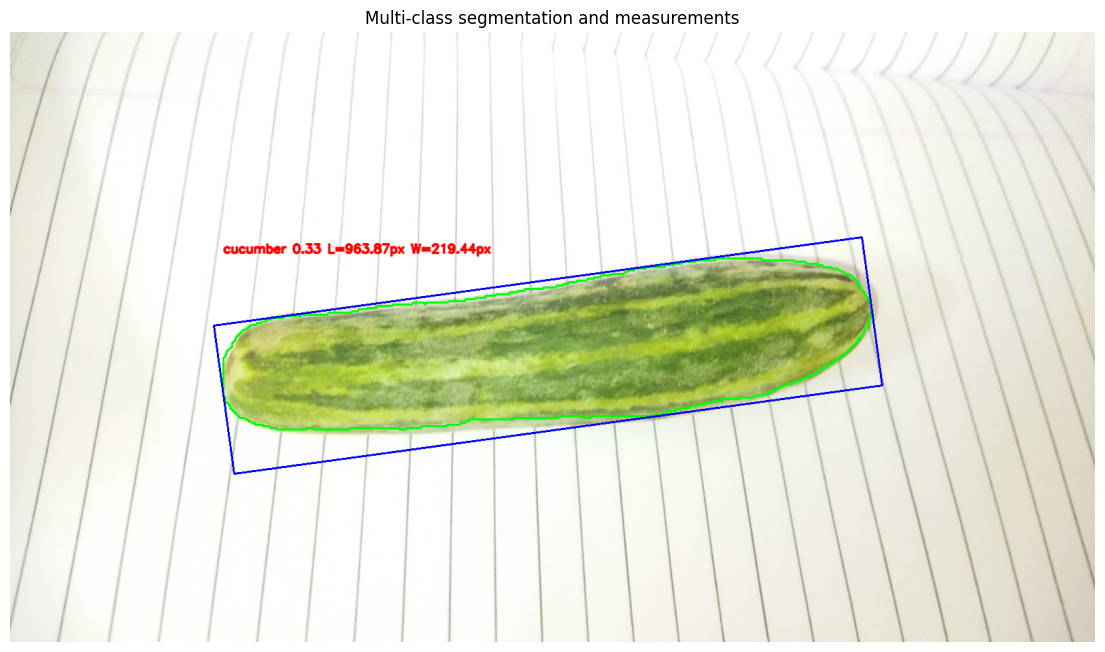

In [21]:
if not uploader.value:
    print("Upload an image using the button above, then run this cell again.")
else:
    uploaded = uploader.value
    # ipywidgets versions differ: value may be a dict or a tuple/list.
    if isinstance(uploaded, dict):
        file_info = next(iter(uploaded.values()))
        image_bytes = file_info["content"]
        filename = file_info.get("metadata", {}).get("name", "uploaded_image")
    else:
        file_info = uploaded[0]
        image_bytes = file_info["content"]
        filename = file_info.get("name", "uploaded_image")

    image_rgb = np.array(Image.open(io.BytesIO(image_bytes)).convert("RGB"))
    image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)

    pixels_per_cm = None
    calibration_message = "Pixel measurements only"
    if REFERENCE_METHOD != "none":
        try:
            pixels_per_cm, calibration_message = get_pixels_per_cm(
                image_bgr,
                method=REFERENCE_METHOD,
                marker_size_cm=ARUCO_MARKER_SIZE_CM,
                dict_name=ARUCO_DICT_NAME
            )
        except Exception as e:
            calibration_message = f"Calibration unavailable: {e}"

    prediction = test_model.predict(
        source=image_bgr,
        imgsz=IMGSZ,
        conf=CONF,
        verbose=False
    )[0]

    annotated = image_bgr.copy()
    measurement_rows = []

    print("Image:", filename)
    print("Calibration:", calibration_message)
    if prediction.masks is None or prediction.boxes is None or len(prediction.boxes) == 0:
        print("No objects detected. Try a clearer image, a supported class, or lower CONF (e.g. 0.10).")
    else:
        for i, polygon in enumerate(prediction.masks.xy):
            class_id = int(prediction.boxes.cls[i].item())
            confidence = float(prediction.boxes.conf[i].item())
            class_name = prediction.names[class_id]
            result = measure_polygon(polygon, pixels_per_cm=pixels_per_cm)
            if result is None:
                continue

            annotated = draw_measurement(
                annotated, polygon, result,
                label=f"{class_name} {confidence:.2f}"
            )
            measurement_rows.append({
                "object_id": i + 1,
                "class": class_name,
                "confidence": round(confidence, 3),
                "length_px": result["length_px"],
                "width_px": result["width_px"],
                "area_px2": result["area_px"],
                "length_cm": result["length_cm"],
                "width_cm": result["width_cm"],
                "area_cm2": result["area_cm2"],
            })

        if measurement_rows:
            display(pd.DataFrame(measurement_rows))
            plt.figure(figsize=(14, 10))
            plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
            plt.title("Multi-class segmentation and measurements")
            plt.axis("off")
            plt.show()
        else:
            print("Detections were returned, but no valid polygon measurements were produced.")

## Notes and limitations

- This notebook trains on the configured 28-class Roboflow dataset, but class performance depends on annotation counts and image variety. Review per-class counts before trusting rare classes.
- Add more images and **polygon segmentation labels** for underrepresented vegetables. Keep train/validation/test images separate.
- For cm, the ArUco marker must be real, clearly visible, correctly sized, and approximately in the same plane/depth as the object. A single scale is inaccurate under strong perspective or varying depth.
- The output is a 2D rotated-rectangle estimate from the visible mask. It is not a full 3D measurement.
- Do not commit or share a notebook containing an API key. Use Kaggle Secrets.
